**project---digit Recognition** **handwritten digits classification using cnn**

**MNIST DATASET--**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
%matplotlib inline



In [2]:
from tensorflow import keras

# Load complete MNIST dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


**missing value check**

In [3]:
np.isnan(X_train).sum()

np.int64(0)

In [4]:
np.isnan(X_test).sum()

np.int64(0)

In [5]:
np.isnan(y_train).sum()

np.int64(0)

**check digit distribution**

In [6]:
unique, counts = np.unique(y_train, return_counts=True)

df = pd.DataFrame({
    "Digit": unique,
    "Count": counts
})

print(df)

   Digit  Count
0      0   5923
1      1   6742
2      2   5958
3      3   6131
4      4   5842
5      5   5421
6      6   5918
7      7   6265
8      8   5851
9      9   5949


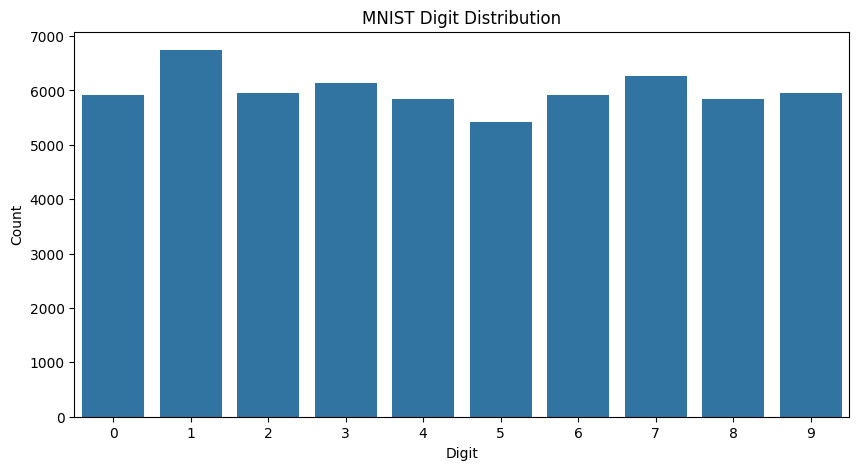

In [7]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x="Digit", y="Count")

plt.title("MNIST Digit Distribution")
plt.xlabel("Digit")
plt.ylabel("Count")

plt.show()

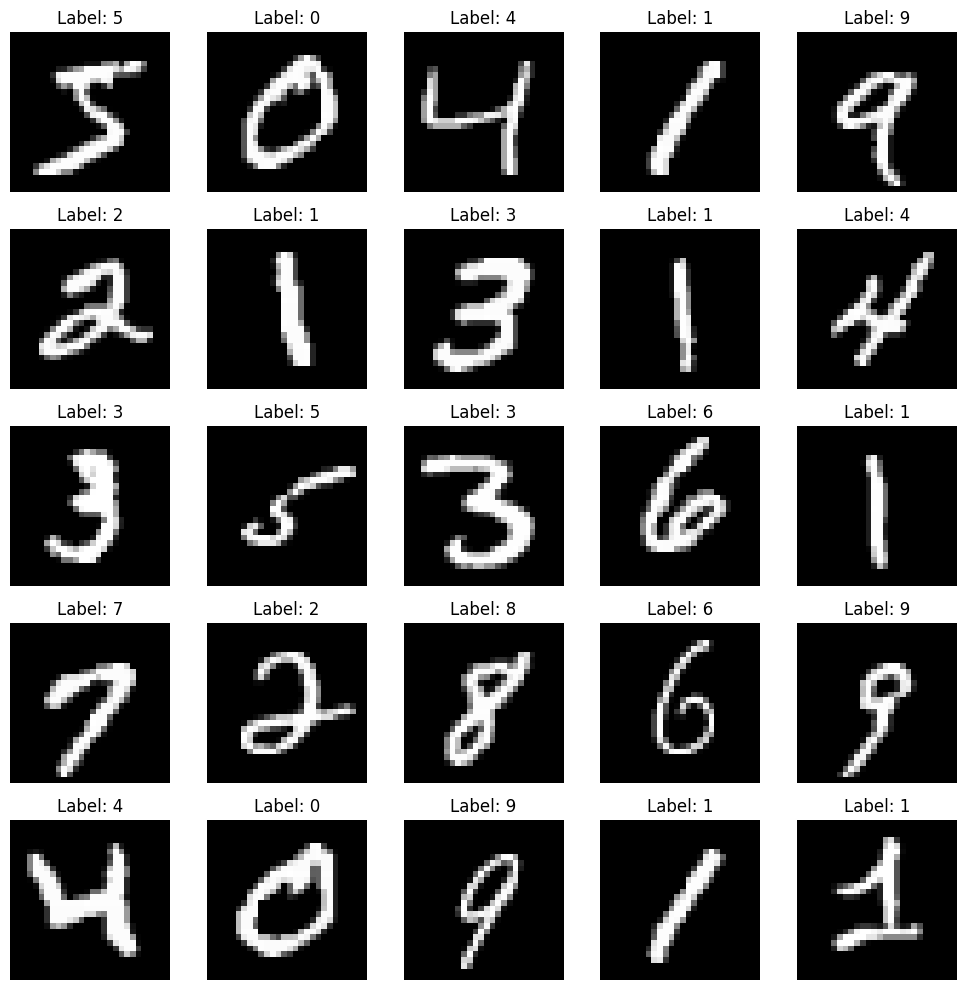

In [8]:
plt.figure(figsize=(10, 10))

for i in range(25):

    plt.subplot(5, 5, i + 1)

    plt.imshow(X_train[i], cmap="gray")

    plt.title(f"Label: {y_train[i]}")

    plt.axis("off")

plt.tight_layout()
plt.show()

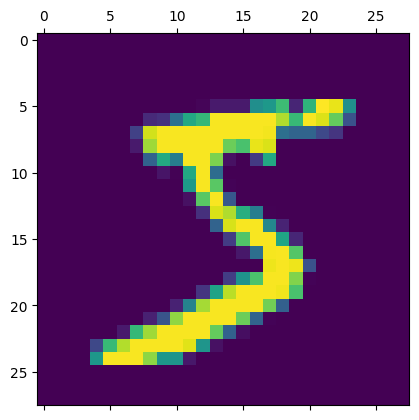

In [9]:
plt.matshow(X_train[0])

In [10]:
X_train = X_train.astype("float32") / 255.0

X_test = X_test.astype("float32") / 255.0

print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

print("Data type:", X_train.dtype)

Minimum: 0.0
Maximum: 1.0
Data type: float32


In [11]:
X_train = X_train.reshape(-1, 28, 28, 1)

X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)


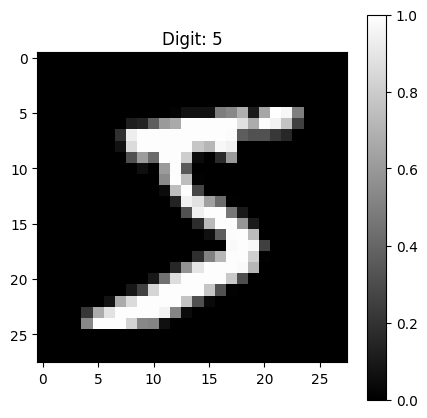

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.imshow(X_train[0].squeeze(), cmap="gray")

plt.title(f"Digit: {y_train[0]}")

plt.colorbar()

plt.show()

In [13]:
import numpy as np

print("Unique Labels:", np.unique(y_train))

print("First 10 Labels:", y_train[:10])

Unique Labels: [0 1 2 3 4 5 6 7 8 9]
First 10 Labels: [5 0 4 1 9 2 1 3 1 4]


In [14]:
from tensorflow.keras import layers

In [15]:
model = keras.Sequential([

    # Input Layer
    keras.Input(shape=(28, 28, 1)),

    # First Convolution Layer
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # First Pooling Layer
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second Convolution Layer
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # Second Pooling Layer
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Flatten Layer
    layers.Flatten(),

    # Fully Connected Layer
    layers.Dense(128, activation="relu"),

    # Dropout
    layers.Dropout(0.3),

    # Output Layer
    layers.Dense(10, activation="softmax")

])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model Compiled Successfully!")

Model Compiled Successfully!


**train cnn model**

In [18]:
# Train CNN model

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9154 - loss: 0.2855 - val_accuracy: 0.9789 - val_loss: 0.0711
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9756 - loss: 0.0798 - val_accuracy: 0.9838 - val_loss: 0.0514
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9817 - loss: 0.0583 - val_accuracy: 0.9880 - val_loss: 0.0413
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9862 - loss: 0.0446 - val_accuracy: 0.9877 - val_loss: 0.0448
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9886 - loss: 0.0373 - val_accuracy: 0.9899 - val_loss: 0.0356
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9900 - loss: 0.0312 - val_accuracy: 0.9891 - val_loss: 0.0368
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9909 - loss: 0.0282 - val_accuracy: 0.9906 - val_loss: 0.0354
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9930 - loss: 0.0238 - val_accuracy: 

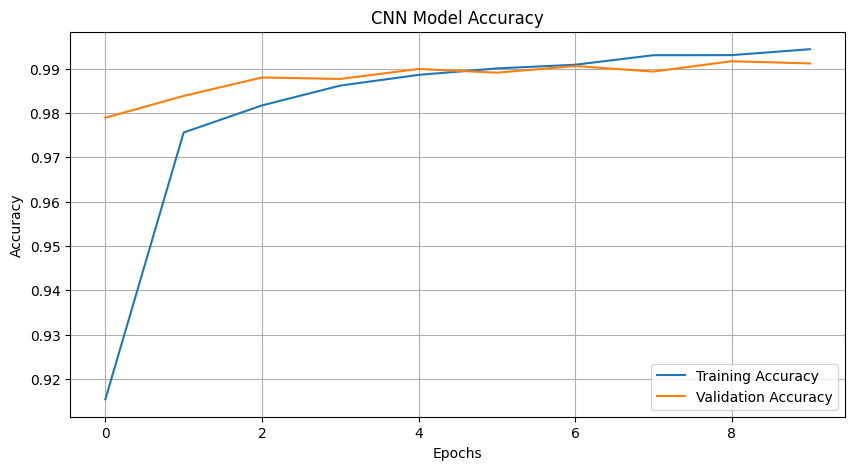

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"],
         label="Training Accuracy")

plt.plot(history.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

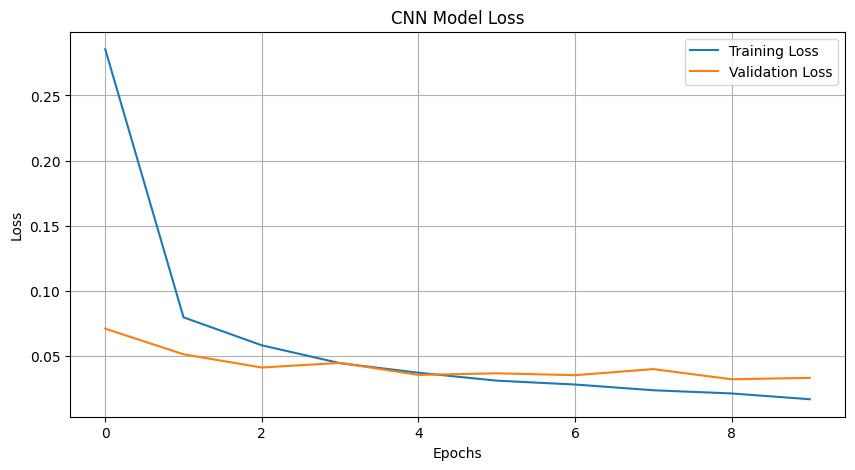

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"],
         label="Training Loss")

plt.plot(history.history["val_loss"],
         label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

In [21]:
model.save("/content/digit_model.keras")

print("Model Saved Successfully!")

Model Saved Successfully!


In [22]:
import os

print(os.path.exists("/content/digit_model.keras"))

True


In [23]:
# test accuracy and loss

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9916 - loss: 0.0267
Test Loss: 0.0267
Test Accuracy: 99.16%


In [24]:
import numpy as np

y_prob = model.predict(X_test)

y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Actual labels: [7 2 1 0 4 1 4 9 5 9]
Predicted labels: [7 2 1 0 4 1 4 9 5 9]


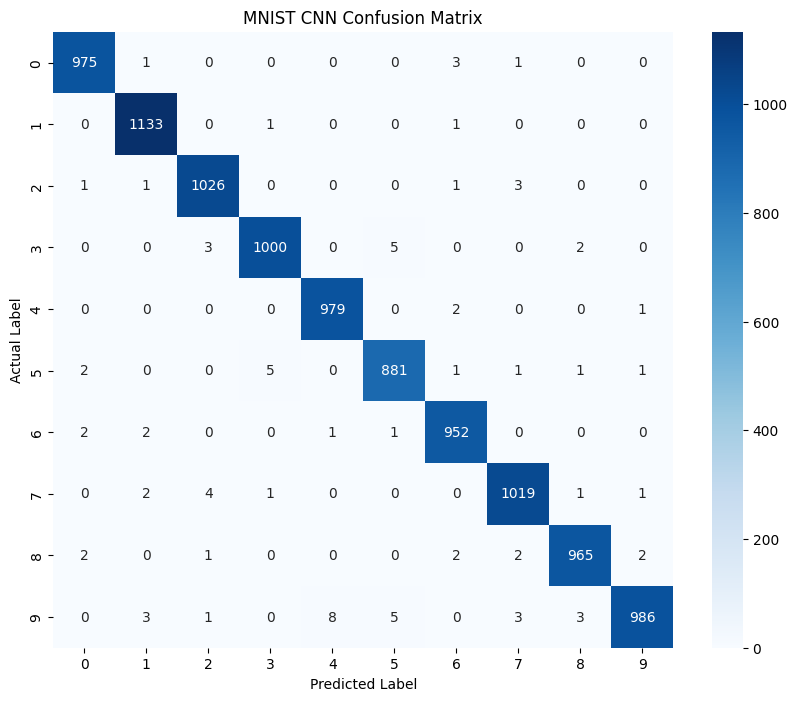

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MNIST CNN Confusion Matrix")

plt.show()

In [26]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9929    0.9949    0.9939       980
           1     0.9921    0.9982    0.9952      1135
           2     0.9913    0.9942    0.9927      1032
           3     0.9930    0.9901    0.9916      1010
           4     0.9909    0.9969    0.9939       982
           5     0.9877    0.9877    0.9877       892
           6     0.9896    0.9937    0.9917       958
           7     0.9903    0.9912    0.9908      1028
           8     0.9928    0.9908    0.9918       974
           9     0.9950    0.9772    0.9860      1009

    accuracy                         0.9916     10000
   macro avg     0.9916    0.9915    0.9915     10000
weighted avg     0.9916    0.9916    0.9916     10000



In [27]:
import os

os.makedirs("/content/models", exist_ok=True)

model.save("/content/models/digit_recognition_model.keras")

print("Model saved successfully!")

Model saved successfully!
